# Debiasing random forest regression predictors: Python demonstration

This notebook demonstrates the `debiasforest` package, a Python implementation of the methods of
Chen, Withana Gamage & Ryan (2022), *Debias Random Forest Regression Predictors*, J. Stat. Research 56(2):115-131.

Methods compared (labels as in the paper):

| Label | Method | Paper section |
|---|---|---|
| Un | uncorrected random forest | 2.1 |
| De, Qu, Cu, Sp | univariate smoothing of `y` on the OOB prediction: linear ("default"), quadratic, cubic, smoothing spline | 2.2.1 |
| Bf, Bf(k) | Breiman's iteratively boosted forest on OOB residuals, with k additional iterations | 2.2.2 |
| Cond | conditional bias correction of Lu & Hardin (2021) | 2.2.3 |

**Run modes.** The default ("thorough") mode uses K=200 simulation replications and 100 Yacht splits.
Set the environment variable `DEBIAS_DEMO_QUICK=1` for a fast smoke run (few replications, fewer trees).
Tables are written to `demo/results/python/` and figures to `demo/figures/python/`.

**Labeling convention.** `n_iterations` is the number of residual forests fitted after the base forest:
`n_iterations=0` is Un, `1` is Bf, and `k+1` is Bf(k) (`paper_label`).

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

from debiasforest import (default_forest, BoostedForestRegressor, SmoothedForestRegressor,
                          ConditionalBiasForestRegressor, simulate, simulation_study,
                          repeated_splits, select_n_iterations, load_yacht, paper_label,
                          bias_plot, predict_all_methods, DatasetUnavailableError)
from debiasforest.evaluation import method_labels

QUICK = os.environ.get("DEBIAS_DEMO_QUICK", "") not in ("", "0")
N_JOBS = 4
SEED = 20220601
if QUICK:
    K, N_SPLITS, N_TREES, K_CURVE, N_SEL = 10, 10, 100, 4, 4
    SIM_CONFIGS = [("f1", 1.0), ("f2", 1.0), ("f4", 1.0)]
else:
    K, N_SPLITS, N_TREES, K_CURVE, N_SEL = 200, 100, 500, 50, 20
    SIM_CONFIGS = [("f1", 1.0), ("f1", 2.0), ("f1", 4.0), ("f2", 1.0), ("f3", 1.0), ("f4", 1.0), ("f5", 1.0)]

# Locate the demo directory so that the notebook runs from the repo root or from demo/.
HERE = Path.cwd()
DEMO = HERE if (HERE / "debias_demo.ipynb").exists() else HERE / "demo"
RES, FIG = DEMO / "results" / "python", DEMO / "figures" / "python"
RES.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
(DEMO / "data").mkdir(exist_ok=True)
os.environ.setdefault("DEBIASFOREST_DATA", str(DEMO / "data"))
T0 = time.time(); TIMINGS = {}
print(f"quick={QUICK}  K={K}  splits={N_SPLITS}  trees={N_TREES}  demo dir={DEMO}")

def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight"); plt.show()

def to_md(df, floatfmt="{:.2f}"):
    # minimal markdown table writer (no tabulate dependency)
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    fmt = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for i, r in df.iterrows():
        lines.append("| " + " | ".join([str(i)] + [fmt(v) for v in r]) + " |")
    return "\n".join(lines) + "\n"

def save_table(df, stem, **kw):
    df.to_csv(RES / f"{stem}.csv"); (RES / f"{stem}.md").write_text(to_md(df, **kw))

quick=False  K=200  splits=100  trees=500  demo dir=/home/user/debias_random_forest/demo


## 1. Figure 1 replica: bias of OOB predictions (paper Section 1, Fig. 1)

Data: n = 500, four U(0,1) predictors, $f(x)=3x_1+x_2^2+\sin(x_3)-\sqrt{x_4}$, noise σ = 0.5.
A random forest shrinks predictions toward the mean: it over-predicts where $f$ is small and under-predicts where $f$ is large.
The plot compares the **out-of-bag** predictions of the uncorrected forest (Un) and the boosted forest (Bf, one residual forest)
with the true $f(x)$; the red line is the 45 degree line. After boosting, the systematic bias at the extremes largely disappears.

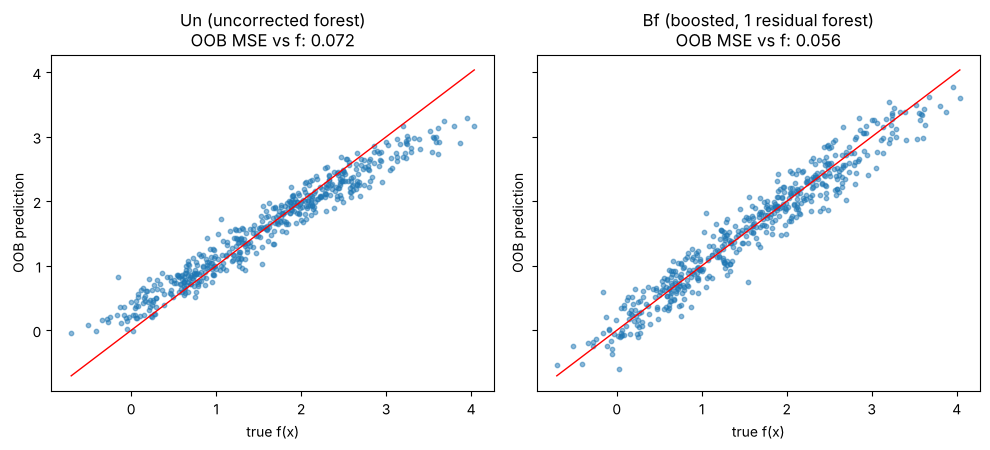

In [2]:
X, y, f = simulate("fig1", 500, sigma=0.5, rng=SEED)
bf = BoostedForestRegressor(n_iterations=1, base_estimator=default_forest(n_estimators=N_TREES),
                            random_state=SEED, n_jobs=N_JOBS).fit(X, y)
oob_un = bf.stage_oob_predictions_[0]; oob_bf = bf.oob_prediction_
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, p, t in zip(axes, (oob_un, oob_bf), ("Un (uncorrected forest)", "Bf (boosted, 1 residual forest)")):
    bias_plot(f, p, ax=ax, xlabel="true f(x)", ylabel="OOB prediction", title=t, alpha=0.5)
    ax.set_title(t + f"\nOOB MSE vs f: {np.mean((p - f)**2):.3f}")
fig.tight_layout(); savefig(fig, "fig1_oob_bias.png")

## 2. Simulation study (paper Section 3, Tables 1 and 2)

For each design (Function 1 with σ ∈ {1, 2, 4}; Functions 2-5 with σ = 1) we use n = 200 training points and n_t = 2000 test points.
`simulation_study` runs K replications; in each, **all** methods are built from one shared base forest. Notes:

* The test predictors are drawn once and **held fixed** across replications; a fresh training set and fresh test noise are drawn each replication.
  MSPE (averaged over test points, then mean and SD over replications) and squared bias
  $\frac1{n_t}\sum_i(\bar{\hat y}_i-f(x_i))^2$ (average prediction over replications) therefore come from the **same set of fits**.
* The paper uses K = 1000 replications; this demo uses K = 200 (thorough mode), so expect Monte Carlo differences in the second decimal.
* Labels: Bf = 1 residual forest, Bf(k) = k+1 residual forests (`n_iterations = k+1`). The paper's Bf and Bf(1) values are nearly identical in
  several rows (e.g. Function 1 sigma=2 and 4, Functions 2, 3, 5); that is a feature of the paper's table. In our runs Bf and Bf(1) come from separate fits (one vs two residual forests), so they are not expected to coincide and the rows can differ more.
* Paper values below are transcribed from Tables 1 and 2 (n = 200 rows only; Function 5 is labeled "MSE" in the paper).

In [3]:
M = method_labels(3)
PAPER = {  # (function, sigma): {stat: values in order Un De Qu Cu Sp Bf Bf(1) Bf(2) Bf(3) Cond}
 ("f1",1.0): dict(MSPE=[6.44,3.92,3.79,3.81,3.83,3.39,2.95,3.13,3.13,3.92], SD=[.42,.41,.34,.34,.46,.29,.23,.26,.33,.34], bias2=[4.76,1.44,1.43,1.42,1.43,1.46,1.46,.74,.53,2.01]),
 ("f1",2.0): dict(MSPE=[9.42,7.11,7.15,7.19,7.20,6.78,6.78,6.87,7.71,7.20], SD=[.71,.5,.51,.51,.57,.46,.46,.44,.54,.52], bias2=[4.36,1.53,1.52,1.53,1.52,1.38,1.39,.77,.57,1.96]),
 ("f1",4.0): dict(MSPE=[21.90,20.58,20.67,20.82,20.81,20.85,20.85,22.94,26.45,20.58], SD=[1.03,.91,.93,.98,1.09,.90,.90,1.14,1.63,.90], bias2=[4.39,1.75,1.73,1.79,1.75,1.22,1.22,.64,.45,1.90]),
 ("f2",1.0): dict(MSPE=[2.01,1.50,1.49,1.50,1.52,1.41,1.41,1.47,1.65,1.49], SD=[.21,.12,.12,.15,.12,.12,.12,.11,.14,.13], bias2=[.79,.15,.14,.13,.14,.11,.11,.02,.01,.21]),
 ("f3",1.0): dict(MSPE=[8.68,4.12,4.15,4.18,4.19,3.49,3.49,2.40,2.46,5.04], SD=[.78,.58,.59,.59,.61,.40,.41,.21,.17,.61], bias2=[6.50,.78,.76,.74,.75,1.34,1.34,.18,.06,2.56]),
 ("f4",1.0): dict(MSPE=[8.83,4.15,4.12,4.14,4.17,3.06,3.07,2.59,2.96,3.76], SD=[1.18,.67,.67,.68,.73,.46,.46,.27,.29,.65], bias2=[7.51,1.30,1.25,1.22,1.23,1.01,1.00,.22,.21,1.80]),
 ("f5",1.0): dict(MSPE=[2.79,2.20,2.20,2.15,2.12,1.68,1.68,1.61,1.80,1.67], SD=[.18,.19,.19,.18,.19,.10,.10,.07,.08,.11], bias2=[1.45,.77,.76,.67,.67,.29,.30,.08,.04,.37]),
}
FNUM = {"f1":"Function 1","f2":"Function 2","f3":"Function 3","f4":"Function 4","f5":"Function 5"}
sim_res, rows = {}, []
t = time.time()
for i, (fn, sg) in enumerate(SIM_CONFIGS):
    r = simulation_study(fn, sigma=sg, n=200, n_test=2000, n_reps=K, random_state=SEED + i,
                         n_jobs=N_JOBS, n_estimators=N_TREES)
    sim_res[(fn, sg)] = r
    name = f"{FNUM[fn]}, sigma={sg:g}"
    for stat, ours in (("MSPE", r.mean), ("SD", r.sd), ("bias2", r.bias2)):
        rows.append([name, stat, "this package"] + list(ours))
        rows.append([name, stat, "paper"] + PAPER[(fn, sg)][stat])
    print(f"{name}: {time.time()-t:.0f}s elapsed")
TIMINGS["simulations"] = time.time() - t
sim_tab = pd.DataFrame(rows, columns=["design", "statistic", "source"] + M).set_index("design")
save_table(sim_tab, "simulation_tables")
sim_tab.round(2)

Function 1, sigma=1: 240s elapsed


Function 1, sigma=2: 502s elapsed


Function 1, sigma=4: 765s elapsed


Function 2, sigma=1: 1053s elapsed


Function 3, sigma=1: 1336s elapsed


Function 4, sigma=1: 1584s elapsed


Function 5, sigma=1: 1830s elapsed


,statistic,source,Un,De,Qu,Cu,Sp,Bf,Bf(1),Bf(2),Bf(3),Cond
design,,,,,,,,,,,,
"Function 1, sigma=1",MSPE,this package,6.34,3.76,3.76,3.78,3.79,3.37,2.92,3.06,3.45,3.97
"Function 1, sigma=1",MSPE,paper,6.44,3.92,3.79,3.81,3.83,3.39,2.95,3.13,3.13,3.92
"Function 1, sigma=1",SD,this package,0.49,0.33,0.33,0.33,0.37,0.28,0.22,0.25,0.34,0.35
"Function 1, sigma=1",SD,paper,0.42,0.41,0.34,0.34,0.46,0.29,0.23,0.26,0.33,0.34
"Function 1, sigma=1",bias2,this package,4.75,1.40,1.39,1.39,1.39,1.50,0.80,0.61,0.52,2.10
"Function 1, sigma=1",bias2,paper,4.76,1.44,1.43,1.42,1.43,1.46,1.46,0.74,0.53,2.01
"Function 1, sigma=2",MSPE,this package,9.73,7.16,7.19,7.23,7.22,6.86,6.79,7.48,8.65,7.40
"Function 1, sigma=2",MSPE,paper,9.42,7.11,7.15,7.19,7.20,6.78,6.78,6.87,7.71,7.20
"Function 1, sigma=2",SD,this package,0.67,0.48,0.48,0.49,0.52,0.42,0.38,0.48,0.69,0.52


The compact view below shows MSPE as "mean (SD)" and bias² for our runs next to the paper's values (design by design). The minimum MSPE per design is marked with `*`.

In [4]:
def compact(r, paper):
    best_o, best_p = np.argmin(r.mean), int(np.argmin(paper["MSPE"]))
    df = pd.DataFrame({
      "ours MSPE (SD)": [f"{m:.2f} ({s:.2f})" + ("*" if j == best_o else "") for j, (m, s) in enumerate(zip(r.mean, r.sd))],
      "ours bias2": [f"{b:.2f}" for b in r.bias2],
      "paper MSPE (SD)": [f"{m:.2f} ({s:.2f})" + ("*" if j == best_p else "") for j, (m, s) in enumerate(zip(paper["MSPE"], paper["SD"]))],
      "paper bias2": [f"{b:.2f}" for b in paper["bias2"]]}, index=M)
    df.index.name = "method"; return df
md_out = []
for key, r in sim_res.items():
    df = compact(r, PAPER[key]); title = f"{FNUM[key[0]]}, sigma={key[1]:g}, n=200, K={K}"
    print(title); print(df.to_string()); print()
    md_out.append(f"### {title}\n\n" + to_md(df))
(RES / "simulation_tables_compact.md").write_text("\n".join(md_out))

Function 1, sigma=1, n=200, K=200
       ours MSPE (SD) ours bias2 paper MSPE (SD) paper bias2
method                                                      
Un        6.34 (0.49)       4.75     6.44 (0.42)        4.76
De        3.76 (0.33)       1.40     3.92 (0.41)        1.44
Qu        3.76 (0.33)       1.39     3.79 (0.34)        1.43
Cu        3.78 (0.33)       1.39     3.81 (0.34)        1.42
Sp        3.79 (0.37)       1.39     3.83 (0.46)        1.43
Bf        3.37 (0.28)       1.50     3.39 (0.29)        1.46
Bf(1)    2.92 (0.22)*       0.80    2.95 (0.23)*        1.46
Bf(2)     3.06 (0.25)       0.61     3.13 (0.26)        0.74
Bf(3)     3.45 (0.34)       0.52     3.13 (0.33)        0.53
Cond      3.97 (0.35)       2.10     3.92 (0.34)        2.01

Function 1, sigma=2, n=200, K=200
       ours MSPE (SD) ours bias2 paper MSPE (SD) paper bias2
method                                                      
Un        9.73 (0.67)       4.99     9.42 (0.71)        4.36
De        7.16 (

4487

**Reading the tables.** As in the paper, almost all of the MSPE improvement over Un comes from lower squared bias; the boosted
forest (Bf, Bf(k)) typically reaches the smallest MSPE at low noise, further iterations keep reducing bias² but add variance
(so MSPE eventually rises, most clearly at σ = 4), and at σ = 4 the noise variance (16) dominates so corrections give negligible gains.

## 3. Effect of the number of iterations (paper Fig. 5 style)

For selected designs and the Yacht data we plot the mean **test** MSPE of the boosted forest against the number of residual forests
$0,1,\dots,6$ (x-axis in the paper's labels: Un, Bf, Bf(1), ...). One boosted forest with six residual forests is fitted per replicate,
and `staged_predict` returns the cumulative prediction after each stage, so the whole curve comes from a single fit.

In [5]:
MAXK = 6
def _curve_rep(fn, sg, seed):
    Xtr, ytr, _ = simulate(fn, 200, sigma=sg, rng=seed)
    Xte, yte, _ = simulate(fn, 2000, sigma=sg, rng=seed + 1)
    with threadpool_limits(1):
        m = BoostedForestRegressor(n_iterations=MAXK, base_estimator=default_forest(n_estimators=N_TREES),
                                   random_state=seed).fit(Xtr, ytr)
        return np.array([np.mean((yte - p) ** 2) for p in m.staged_predict(Xte)])
curves, t = {}, time.time()
curve_cfg = [("f1", 1.0), ("f3", 1.0)] if not QUICK else [("f1", 1.0)]
for i, (fn, sg) in enumerate(curve_cfg):
    out = Parallel(n_jobs=N_JOBS)(delayed(_curve_rep)(fn, sg, SEED + 1000 * (i + 1) + 2 * j) for j in range(K_CURVE))
    curves[f"{FNUM[fn]} (sigma={sg:g})"] = np.array(out)
TIMINGS["curves_sim"] = time.time() - t
print({k: v.shape for k, v in curves.items()})

{'Function 1 (sigma=1)': (50, 7), 'Function 3 (sigma=1)': (50, 7)}


## 4. Real data: Yacht hydrodynamics (paper Section 4, Tables 3-4, Fig. 3)

The UCI Yacht data (308 rows, 6 predictors, response = residuary resistance) is downloaded on first use and cached in `demo/data/`
(UCI first, then a GitHub mirror). If it cannot be downloaded, this section and the Yacht curve are skipped.
Each of the 100 replications draws a random 2/3 train, 1/3 test split and records the test MSPE of every method.
Paper Table 4 (Yacht row, 1000 replications) is shown for comparison; Bf(3) is not reported there.

In [6]:
PAPER_YACHT = {"Un":(12.89,4.65),"De":(5.75,1.58),"Qu":(5.36,1.45),"Cu":(4.52,1.63),"Sp":(4.08,1.62),
               "Bf":(1.69,0.99),"Bf(1)":(1.55,0.69),"Bf(2)":(2.19,0.81),"Bf(3)":None,"Cond":(3.46,2.24)}
try:
    Xy, yy = load_yacht(cache_dir=DEMO / "data"); YACHT = True
    print("Yacht loaded:", Xy.shape)
except DatasetUnavailableError as e:
    YACHT = False; print("Yacht data unavailable, skipping the Yacht parts:", e)

Yacht loaded: (308, 6)


In [7]:
if YACHT:
    t = time.time()
    sp = repeated_splits(Xy, yy, n_splits=N_SPLITS, test_size=1/3, random_state=SEED, n_jobs=N_JOBS, n_estimators=N_TREES)
    TIMINGS["yacht_splits"] = time.time() - t
    cell = lambda m, s: f"{m:.2f} ({s:.2f})"
    yt = pd.DataFrame({"this package, MSPE (SD)": [cell(m, s) for m, s in zip(sp.mean, sp.sd)],
                       "paper Table 4, MSPE (SD)": ["-" if PAPER_YACHT[l] is None else cell(*PAPER_YACHT[l]) for l in sp.labels]},
                      index=sp.labels).T
    yt.index.name = "Yacht"
    yt.to_csv(RES / "yacht_table.csv"); (RES / "yacht_table.md").write_text(to_md(yt))
    pd.DataFrame(sp.mspe, columns=sp.labels).to_csv(RES / "yacht_split_mspe.csv", index_label="split")
    print(f"{N_SPLITS} random splits, {time.time()-t:.0f}s"); print(yt.to_string())

100 random splits, 97s
                                    Un            De           Qu           Cu             Sp           Bf        Bf(1)        Bf(2)        Bf(3)         Cond
Yacht                                                                                                                                                         
this package, MSPE (SD)   18.20 (6.74)  10.63 (3.65)  9.90 (3.42)  8.93 (4.05)  18.57 (38.75)  3.45 (1.82)  2.92 (1.37)  3.84 (1.80)  5.86 (2.72)  5.94 (2.82)
paper Table 4, MSPE (SD)  12.89 (4.65)   5.75 (1.58)  5.36 (1.45)  4.52 (1.63)    4.08 (1.62)  1.69 (0.99)  1.55 (0.69)  2.19 (0.81)            -  3.46 (2.24)


**Predicted vs observed on one split (paper Fig. 3).** We fit all methods on one training split and plot test predictions against
observed responses for Un, the best univariate smoother (lowest test MSPE among De, Qu, Cu, Sp on this split) and Bf.
Un shows the typical forest bias (over-predicting small and under-predicting large responses); boosting moves the cloud closer to the 45 degree line.

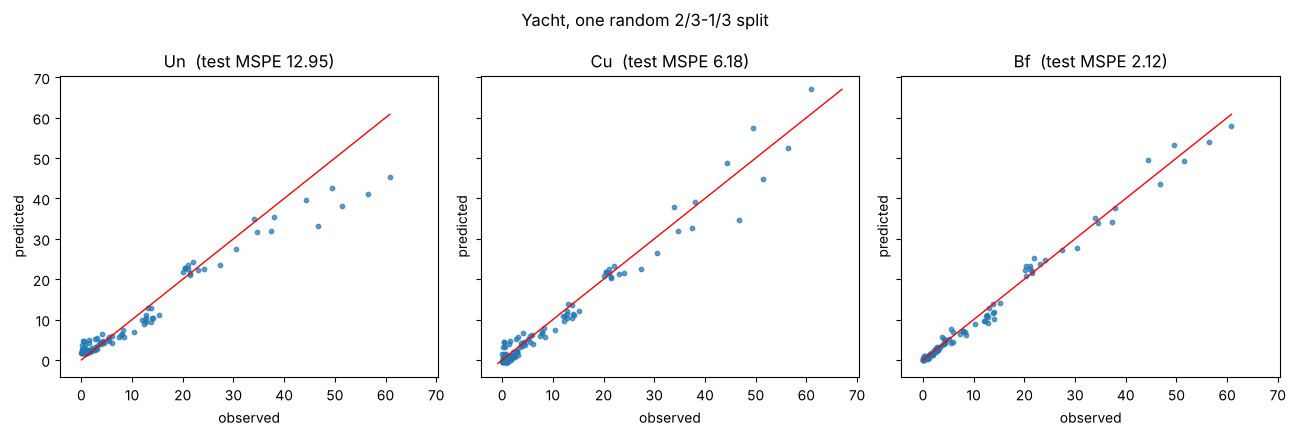

In [8]:
if YACHT:
    rng = np.random.RandomState(SEED); idx = rng.permutation(len(yy)); nte = len(yy) // 3
    te, tr = idx[:nte], idx[nte:]
    with threadpool_limits(1):
        P = predict_all_methods(Xy[tr], yy[tr], Xy[te], random_state=SEED, n_estimators=N_TREES)
    mspe1 = {l: np.mean((yy[te] - p) ** 2) for l, p in P.items()}
    best_uni = min(("De", "Qu", "Cu", "Sp"), key=mspe1.get)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
    for ax, l in zip(axes, ("Un", best_uni, "Bf")):
        bias_plot(yy[te], P[l], ax=ax, xlabel="observed", ylabel="predicted", title=f"{l}  (test MSPE {mspe1[l]:.2f})", alpha=0.7)
    fig.suptitle("Yacht, one random 2/3-1/3 split"); fig.tight_layout(); savefig(fig, "yacht_pred_vs_obs.png")

**Choosing the number of iterations.** `select_n_iterations` implements the paper's practical rule (Section 4): over repeated random
splits it averages the test MSPE of the boosted forest for k = 0..6 residual forests and selects the first k whose mean MSPE is below that at k+1
(i.e. stop when the mean first increases). The resulting curve is also the Yacht curve of Fig. 5 (x axis in paper labels).

In [9]:
if YACHT:
    t = time.time()
    sel = select_n_iterations(Xy, yy, max_iterations=MAXK, n_splits=max(N_SEL, N_SPLITS if not QUICK else N_SEL),
                              random_state=SEED, n_jobs=N_JOBS, n_estimators=N_TREES)
    TIMINGS["select"] = time.time() - t
    print(f"selected n_iterations = {sel.n_iterations}  (paper label {paper_label(sel.n_iterations)})")
    sel_df = pd.DataFrame({"mean_MSPE": sel.mean_mspe, "sd_MSPE": sel.sd_mspe}, index=[paper_label(k) for k in range(MAXK + 1)])
    sel_df.index.name = "n_iterations"
    save_table(sel_df, "yacht_select_n_iterations", floatfmt="{:.3f}")
    curves["Yacht"] = sel.mspe
    print(sel_df.round(3).to_string())

selected n_iterations = 2  (paper label Bf(1))
              mean_MSPE  sd_MSPE
n_iterations                    
Un               18.204    6.741
Bf                3.458    1.801
Bf(1)             2.890    1.351
Bf(2)             3.801    1.743
Bf(3)             5.841    2.615
Bf(4)             9.164    3.888
Bf(5)            14.350    6.054


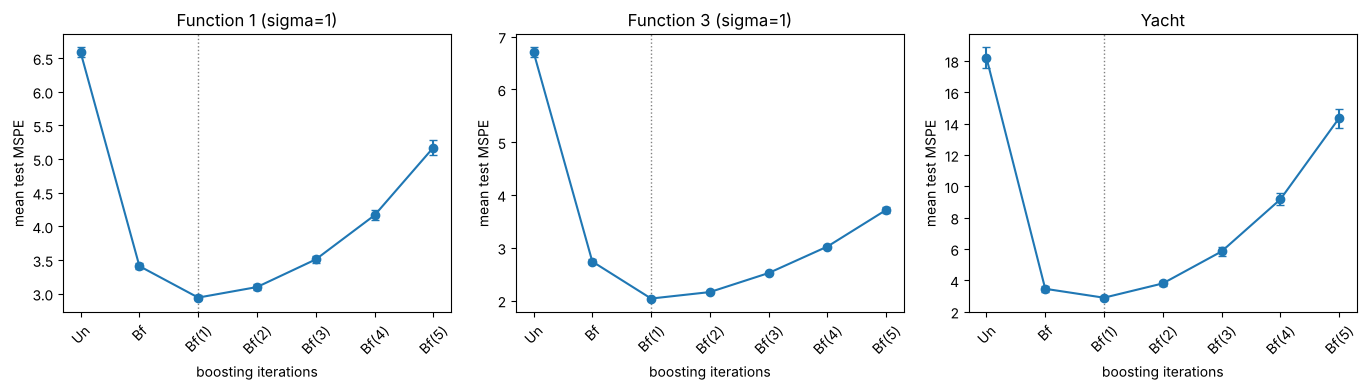

,Function 1 (sigma=1),Function 3 (sigma=1),Yacht
n_iterations,,,
Un,6.586,6.709,18.204
Bf,3.409,2.738,3.458
Bf(1),2.942,2.038,2.890
Bf(2),3.098,2.160,3.801
Bf(3),3.509,2.521,5.841
Bf(4),4.165,3.023,9.164
Bf(5),5.170,3.717,14.350


In [10]:
labels = [paper_label(k) for k in range(MAXK + 1)]
fig, axes = plt.subplots(1, len(curves), figsize=(4.6 * len(curves), 4), squeeze=False)
for ax, (name, c) in zip(axes[0], curves.items()):
    mu = c.mean(0); se = c.std(0, ddof=1) / np.sqrt(len(c)) if len(c) > 1 else 0 * mu
    ax.errorbar(range(MAXK + 1), mu, yerr=se, marker="o", capsize=3)
    ax.set_xticks(range(MAXK + 1)); ax.set_xticklabels(labels, rotation=45)
    ax.axvline(int(np.argmin(mu)), color="gray", ls=":", lw=1)
    ax.set_title(name); ax.set_xlabel("boosting iterations"); ax.set_ylabel("mean test MSPE")
fig.tight_layout(); savefig(fig, "iteration_curves.png")
cdf = pd.DataFrame({k: v.mean(0) for k, v in curves.items()}, index=labels); cdf.index.name = "n_iterations"
save_table(cdf, "iteration_curves", floatfmt="{:.3f}"); cdf.round(3)

The curves show the pattern discussed in the paper: the MSPE drops sharply after the first residual forest(s), reaches a minimum after very few iterations
(compare the argmin dotted line and the selected n_iterations above), and then rises as further forests add variance. Exact minimizers vary with the run (see the saved tables).

In [11]:
TIMINGS["total"] = time.time() - T0
print({k: f"{v:.0f}s" for k, v in TIMINGS.items()})
pd.Series(TIMINGS, name="seconds").to_csv(RES / "timings.csv")

{'simulations': '1830s', 'curves_sim': '147s', 'yacht_splits': '97s', 'select': '129s', 'total': '2208s'}
